# 03 — Modeling

Trains and compares two forecasters on the feature set built in [`02_feature_engineering.ipynb`](02_feature_engineering.ipynb):

1. **Seasonal naive baseline** — "sales will be what they were on the same weekday last week" (`sales_lag_7`). Any model that can't beat this isn't earning its complexity.
2. **LightGBM** — gradient-boosted trees, the standard strong learner for tabular time series: handles nonlinearities, feature interactions and categorical `store`/`item` natively.

**Validation is time-based**: train on 2014-01 → 2017-09, validate on the final quarter (2017-10 → 2017-12). Shuffled splits would leak the future into training and produce dishonestly good scores.

> **Scope note:** lag/rolling features here use values up to the previous day, so this evaluates **1-day-ahead** accuracy. Multi-horizon backtesting (predicting 90 days out, as in the original Kaggle challenge) is the subject of `04_evaluation.ipynb`.

- **Input:** `data/processed/features.parquet`
- **Outputs:** metrics → `outputs/metrics/`, predictions → `outputs/forecasts/`, figures → `outputs/figures/`

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

from src.evaluation.metrics import evaluate
from src.models.train import train_lgbm

PALETTE = ["#2a78d6", "#008300", "#e87ba4", "#eda100", "#1baf7a", "#eb6834", "#4a3aa7", "#e34948"]
BLUE, GREEN = PALETTE[0], PALETTE[1]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

FIG_DIR = Path("../outputs/figures")
METRICS_DIR = Path("../outputs/metrics")
FORECASTS_DIR = Path("../outputs/forecasts")
for d in (FIG_DIR, METRICS_DIR, FORECASTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_parquet("../data/processed/features.parquet")
df["store"] = df["store"].astype("category")
df["item"] = df["item"].astype("category")

SPLIT_DATE = "2017-10-01"
train = df[df["date"] < SPLIT_DATE]
valid = df[df["date"] >= SPLIT_DATE]

FEATURES = [c for c in df.columns if c not in ("date", "sales")]
TARGET = "sales"

print(f"Train: {len(train):,} rows  ({train['date'].min().date()} to {train['date'].max().date()})")
print(f"Valid: {len(valid):,} rows  ({valid['date'].min().date()} to {valid['date'].max().date()})")
print(f"{len(FEATURES)} features")

Train: 684,500 rows  (2014-01-01 to 2017-09-30)
Valid: 46,000 rows  (2017-10-01 to 2017-12-31)
23 features


## 1. Metrics

- **SMAPE** (symmetric mean absolute percentage error) — the official metric of the Kaggle challenge; scale-independent, so a busy store and a quiet one weigh equally.
- **MAE** — absolute error in units sold; easy to reason about operationally.
- **RMSE** — punishes large misses; sensitive to peak days.

The implementations live in [`src/evaluation/metrics.py`](../src/evaluation/metrics.py) and are unit-tested in [`tests/test_metrics.py`](../tests/test_metrics.py).

In [3]:
results = []

## 2. Baseline — seasonal naive

Prediction = sales on the same weekday one week earlier. Zero parameters, zero training. This is the bar to clear.

In [4]:
baseline_pred = valid["sales_lag_7"].to_numpy()
results.append(evaluate("Seasonal naive (lag-7)", valid[TARGET].to_numpy(), baseline_pred))
pd.DataFrame(results).round(2)

,model,SMAPE,MAE,RMSE
0,Seasonal naive (lag-7),18.56,9.08,12.05


## 3. LightGBM

MAE objective (robust for count data), 63 leaves, early stopping on the validation quarter. `store` and `item` enter as native categorical features — LightGBM learns per-series level differences without one-hot explosion. Training is wrapped by [`src/models/train.py`](../src/models/train.py).

In [5]:
model = train_lgbm(train[FEATURES], train[TARGET], valid[FEATURES], valid[TARGET])

lgbm_pred = model.predict(valid[FEATURES], num_iteration=model.best_iteration_)
results.append(evaluate("LightGBM", valid[TARGET].to_numpy(), lgbm_pred))
print(f"Best iteration: {model.best_iteration_}")
pd.DataFrame(results).round(2)

Best iteration: 1463


,model,SMAPE,MAE,RMSE
0,Seasonal naive (lag-7),18.56,9.08,12.05
1,LightGBM,12.44,5.91,7.66


## 4. What the model learned

Gain-based importance: how much each feature contributed to reducing the loss.

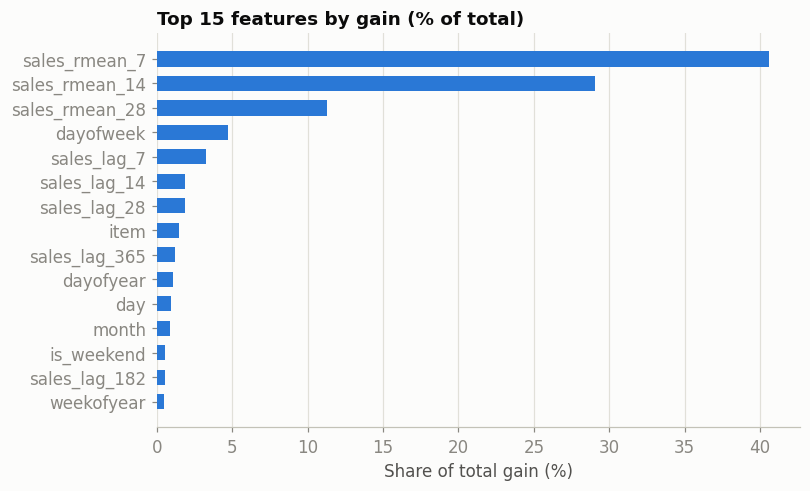

In [6]:
imp = (pd.Series(model.booster_.feature_importance(importance_type="gain"), index=FEATURES)
         .sort_values().tail(15))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(imp.index, imp.values / imp.values.sum() * 100, color=BLUE, height=0.62)
ax.set_title("Top 15 features by gain (% of total)")
ax.set_xlabel("Share of total gain (%)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "mod_01_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Predictions vs. actuals

Two views: total demand across all 500 series (does the model track the aggregate?), and one individual series (does it track the noisy unit it actually predicts?).

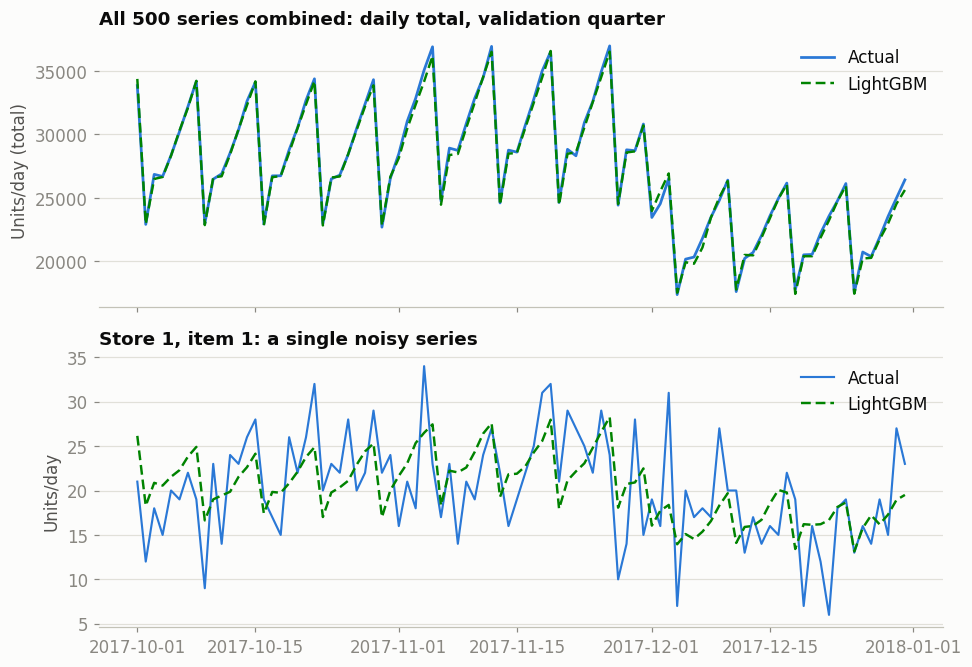

In [7]:
vp = valid[["date", "store", "item", "sales"]].copy()
vp["pred_naive"] = baseline_pred
vp["pred_lgbm"] = lgbm_pred

daily = vp.groupby("date")[["sales", "pred_lgbm"]].sum()
one = vp[(vp["store"] == 1) & (vp["item"] == 1)].set_index("date")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True)

ax1.plot(daily.index, daily["sales"], color=BLUE, linewidth=1.8, label="Actual")
ax1.plot(daily.index, daily["pred_lgbm"], color=GREEN, linewidth=1.6,
         linestyle=(0, (4, 2)), label="LightGBM")
ax1.set_title("All 500 series combined: daily total, validation quarter")
ax1.set_ylabel("Units/day (total)")
ax1.legend(frameon=False, loc="upper right")
ax1.grid(axis="y")
ax1.grid(axis="x", visible=False)

ax2.plot(one.index, one["sales"], color=BLUE, linewidth=1.4, label="Actual")
ax2.plot(one.index, one["pred_lgbm"], color=GREEN, linewidth=1.6,
         linestyle=(0, (4, 2)), label="LightGBM")
ax2.set_title("Store 1, item 1: a single noisy series")
ax2.set_ylabel("Units/day")
ax2.legend(frameon=False, loc="upper right")
ax2.grid(axis="y")
ax2.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(FIG_DIR / "mod_02_pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Persist results

In [8]:
metrics = pd.DataFrame(results).round(3)
metrics.to_csv(METRICS_DIR / "validation_metrics.csv", index=False)
vp.to_parquet(FORECASTS_DIR / "validation_predictions.parquet", index=False)

improvement = (1 - metrics.loc[1, "SMAPE"] / metrics.loc[0, "SMAPE"]) * 100
print(f"LightGBM improves SMAPE by {improvement:.0f}% over the seasonal naive baseline")
metrics

LightGBM improves SMAPE by 33% over the seasonal naive baseline


,model,SMAPE,MAE,RMSE
0,Seasonal naive (lag-7),18.561,9.076,12.051
1,LightGBM,12.438,5.911,7.661


## Summary

| Model | SMAPE | MAE | RMSE |
|---|---|---|---|
| Seasonal naive (lag-7) | 18.56 | 9.08 | 12.05 |
| **LightGBM** | **12.44** | **5.91** | **7.66** |

- The **seasonal naive** baseline is respectable (SMAPE 18.6) — weekly seasonality alone explains a lot of retail demand.
- **LightGBM cuts SMAPE by 33%** (18.6 -> 12.4) by combining recent rolling levels, weekly-aligned lags and calendar effects, with `store`/`item` capturing per-series levels.
- Feature importance confirms the EDA story: the recent rolling means dominate (`sales_rmean_7/14/28` = ~80% of total gain) and `dayofweek` carries the weekly cycle.

**Caveat:** these are 1-day-ahead scores. Errors compound over longer horizons — `04_evaluation.ipynb` backtests a realistic 90-day horizon with horizon-safe features.